# Skin Cancer Classification — corrected preprocessing notebook

**Important:** Run the notebook from the beginning after opening it in your runtime. Previous outputs were cleared because they reflected the merge bug. The ISIC sample now gets its image paths before concatenation, and row-count assertions stop execution if images are silently dropped.\n
The ISIC2019 metadata in this dataset has `patient_id = -1` for all records, so ISIC images are grouped by image rather than patient/lesion. HAM10000 images are grouped by `lesion_id`.\n

In [1]:
import os
from pathlib import Path
from getpass import getpass

token = getpass("Enter your Kaggle API token: ")

kaggle_dir = Path.home() / ".kaggle"
kaggle_dir.mkdir(parents=True, exist_ok=True)

token_path = kaggle_dir / "access_token"
token_path.write_text(token.strip())
token_path.chmod(0o600)

os.environ["KAGGLE_API_TOKEN"] = token.strip()

print("Kaggle credentials configured.")

Enter your Kaggle API token:  ········


Kaggle credentials configured.


In [2]:
!pip -q install -U kaggle

In [3]:
import os

os.makedirs("/content/isic", exist_ok=True)

!kaggle datasets download \
    -d cdeotte/jpeg-isic2019-512x512 \
    -p /content/isic \
    --unzip

Dataset URL: https://www.kaggle.com/datasets/cdeotte/jpeg-isic2019-512x512
License(s): CC0-1.0
100%|███████████████████████████████████████| 1.38G/1.38G [00:06<00:00, 212MB/s]



In [4]:
import os

ROOT = "/content/isic"

if not os.path.exists(ROOT):
    print("ERROR: Dataset folder does not exist.")
else:
    for current_root, dirs, filenames in os.walk(ROOT):
        level = current_root.replace(ROOT, "").count(os.sep)

        if level > 2:
            dirs[:] = []
            continue

        print(f"\nFolder: {current_root}")

        for filename in filenames[:10]:
            print("  ", filename)

        if len(filenames) > 10:
            print(f"  ... and {len(filenames) - 10} more files")


Folder: /content/isic
   train.csv

Folder: /content/isic/train
   ISIC_0032061.jpg
   ISIC_0028105.jpg
   ISIC_0012473_downsampled.jpg
   ISIC_0072340.jpg
   ISIC_0028225.jpg
   ISIC_0061199.jpg
   ISIC_0012939_downsampled.jpg
   ISIC_0014522_downsampled.jpg
   ISIC_0058574.jpg
   ISIC_0029651.jpg
  ... and 25321 more files


In [5]:
import os

csv_files = []

for current_root, _, filenames in os.walk(ROOT):
    for filename in filenames:
        if filename.lower().endswith(".csv"):
            csv_files.append(os.path.join(current_root, filename))

print("CSV files found:", len(csv_files))

for path in csv_files:
    print(path)

CSV files found: 1
/content/isic/train.csv


In [6]:
import pandas as pd
import os

CSV_PATH = "/content/isic/train.csv"

df = pd.read_csv(CSV_PATH)

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (25331, 11)

Column names:
['image_name', 'patient_id', 'sex', 'age_approx', 'anatom_site_general_challenge', 'diagnosis', 'benign_malignant', 'target', 'tfrecord', 'width', 'height']

First 5 rows:


,image_name,patient_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target,tfrecord,width,height
0,ISIC_0000000,-1,female,55.0,anterior torso,NV,benign,0,4,1022,767
1,ISIC_0000001,-1,female,30.0,anterior torso,NV,benign,0,18,1022,767
2,ISIC_0000002,-1,female,60.0,upper extremity,MEL,malignant,1,0,1022,767
3,ISIC_0000003,-1,male,30.0,upper extremity,NV,benign,0,24,1022,767
4,ISIC_0000004,-1,male,80.0,posterior torso,MEL,malignant,1,14,1022,767



Data types:
image_name                        object
patient_id                         int64
sex                               object
age_approx                       float64
anatom_site_general_challenge     object
diagnosis                         object
benign_malignant                  object
target                             int64
tfrecord                           int64
width                              int64
height                             int64
dtype: object

Missing values:


anatom_site_general_challenge    2631
age_approx                        437
image_name                          0
sex                                 0
patient_id                          0
diagnosis                           0
benign_malignant                    0
target                              0
tfrecord                            0
width                               0
height                              0
dtype: int64


Duplicate rows: 0


In [7]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/isic")
IMAGE_DIR = ROOT / "train"

# 1. Distribution of diagnosis classes
print("=== Diagnosis Distribution ===")

diagnosis_counts = df["diagnosis"].value_counts(dropna=False)

diagnosis_report = pd.DataFrame({
    "image_count": diagnosis_counts,
    "percentage": (
        diagnosis_counts / len(df) * 100
    ).round(2)
})

display(diagnosis_report)

# 2. Binary target distribution
print("\n=== Benign / Malignant Distribution ===")

display(pd.DataFrame({
    "image_count": df["benign_malignant"].value_counts(),
    "percentage": (
        df["benign_malignant"].value_counts(normalize=True) * 100
    ).round(2)
}))

# 3. Check consistency between binary labels
print("\n=== Label Consistency ===")

print(
    "Target values:",
    sorted(df["target"].unique())
)

print("\nDiagnosis vs benign_malignant:")
display(pd.crosstab(df["diagnosis"], df["benign_malignant"]))

print("\nTarget vs benign_malignant:")
display(pd.crosstab(df["target"], df["benign_malignant"]))

# 4. Duplicate image identifiers
print("\n=== Duplicate Identifiers ===")

print("Duplicate image_name:", df["image_name"].duplicated().sum())

# 5. Check patient identifiers
print("\n=== Patient IDs ===")

print("Unknown patient IDs (-1):", (df["patient_id"] == -1).sum())
print("Unique patient IDs including -1:", df["patient_id"].nunique())
print("Missing patient IDs:", df["patient_id"].isna().sum())

# 6. Check image file existence
print("\n=== Image File Matching ===")

available_files = {
    p.name for p in IMAGE_DIR.iterdir() if p.is_file()
}

def find_image_file(image_name):
    candidates = [
        f"{image_name}.jpg",
        f"{image_name}_downsampled.jpg"
    ]

    for name in candidates:
        if name in available_files:
            return name

    return None

df["matched_filename"] = df["image_name"].apply(find_image_file)

missing_images = df["matched_filename"].isna()

print("CSV rows:", len(df))
print("Images matched:", (~missing_images).sum())
print("Images missing:", missing_images.sum())

if missing_images.any():
    display(df.loc[missing_images, ["image_name", "diagnosis"]].head(10))

=== Diagnosis Distribution ===


,image_count,percentage
diagnosis,,
NV,12875,50.83
MEL,4522,17.85
BCC,3323,13.12
BKL,2624,10.36
AK,867,3.42
SCC,628,2.48
VASC,253,1.00
DF,239,0.94



=== Benign / Malignant Distribution ===


,image_count,percentage
benign_malignant,,
benign,20809,82.15
malignant,4522,17.85



=== Label Consistency ===
Target values: [np.int64(0), np.int64(1)]

Diagnosis vs benign_malignant:


benign_malignant,benign,malignant
diagnosis,,
AK,867,0
BCC,3323,0
BKL,2624,0
DF,239,0
MEL,0,4522
NV,12875,0
SCC,628,0
VASC,253,0



Target vs benign_malignant:


benign_malignant,benign,malignant
target,,
0,20809,0
1,0,4522



=== Duplicate Identifiers ===
Duplicate image_name: 0

=== Patient IDs ===
Unknown patient IDs (-1): 25331
Unique patient IDs including -1: 1
Missing patient IDs: 0

=== Image File Matching ===
CSV rows: 25331
Images matched: 25331
Images missing: 0


In [8]:
from PIL import Image
from collections import Counter
from tqdm.auto import tqdm
from pathlib import Path
import pandas as pd

ROOT = Path("/content/isic")
IMAGE_DIR = ROOT / "train"

image_checks = []

for filename in tqdm(df["matched_filename"], desc="Checking images"):
    image_path = IMAGE_DIR / filename

    try:
        with Image.open(image_path) as img:
            image_checks.append({
                "filename": filename,
                "status": "OK",
                "format": img.format,
                "width": img.width,
                "height": img.height,
                "mode": img.mode
            })

    except Exception as e:
        image_checks.append({
            "filename": filename,
            "status": "CORRUPTED",
            "format": None,
            "width": None,
            "height": None,
            "mode": None
        })

image_report = pd.DataFrame(image_checks)

print("=== Image Integrity ===")
print(image_report["status"].value_counts())

print("\n=== Image Dimensions ===")
display(
    image_report
    .groupby(["width", "height"], dropna=False)
    .size()
    .reset_index(name="image_count")
    .sort_values("image_count", ascending=False)
)

print("\n=== Image Formats ===")
display(image_report["format"].value_counts(dropna=False))

print("\n=== Image Modes ===")
display(image_report["mode"].value_counts(dropna=False))

print("\n=== Corrupted Images ===")
display(
    image_report[image_report["status"] == "CORRUPTED"].head(10)
)

Checking images:   0%|          | 0/25331 [00:00<?, ?it/s]

=== Image Integrity ===
status
OK    25331
Name: count, dtype: int64

=== Image Dimensions ===


,width,height,image_count
0,512,512,25331



=== Image Formats ===


format
JPEG    25331
Name: count, dtype: int64


=== Image Modes ===


mode
RGB    25331
Name: count, dtype: int64


=== Corrupted Images ===


,filename,status,format,width,height,mode


In [9]:
import hashlib
from collections import defaultdict
from tqdm.auto import tqdm

# 1. Calculate a unique hash for each image file
hash_to_images = defaultdict(list)

for filename in tqdm(df["matched_filename"], desc="Hashing images"):
    image_path = IMAGE_DIR / filename

    with open(image_path, "rb") as f:
        file_hash = hashlib.sha256(f.read()).hexdigest()

    hash_to_images[file_hash].append(filename)

# 2. Keep groups containing more than one identical file
duplicate_groups = {
    file_hash: filenames
    for file_hash, filenames in hash_to_images.items()
    if len(filenames) > 1
}

print("=== Exact Duplicate Check ===")
print("Total images:", len(df))
print("Unique file hashes:", len(hash_to_images))
print("Duplicate groups:", len(duplicate_groups))
print(
    "Images involved in duplicate groups:",
    sum(len(files) for files in duplicate_groups.values())
)

# 3. Inspect duplicate groups alongside their labels
duplicate_rows = []

for file_hash, filenames in duplicate_groups.items():
    for filename in filenames:
        row = df.loc[df["matched_filename"] == filename].iloc[0]

        duplicate_rows.append({
            "file_hash": file_hash,
            "filename": filename,
            "image_name": row["image_name"],
            "diagnosis": row["diagnosis"],
            "patient_id": row["patient_id"]
        })

duplicate_report = pd.DataFrame(duplicate_rows)

if not duplicate_report.empty:
    display(duplicate_report.sort_values("file_hash"))

    print("\n=== Label Conflicts ===")
    label_conflicts = (
        duplicate_report.groupby("file_hash")["diagnosis"]
        .nunique()
    )
    print("Duplicate groups with conflicting diagnoses:",
          (label_conflicts > 1).sum())
else:
    print("No exact duplicate files found.")

Hashing images:   0%|          | 0/25331 [00:00<?, ?it/s]

=== Exact Duplicate Check ===
Total images: 25331
Unique file hashes: 25281
Duplicate groups: 50
Images involved in duplicate groups: 100


,file_hash,filename,image_name,diagnosis,patient_id
40,00d4e8448f755ab9a42a4dc75922d484abdb8e01d83266...,ISIC_0058770.jpg,ISIC_0058770,MEL,-1
41,00d4e8448f755ab9a42a4dc75922d484abdb8e01d83266...,ISIC_0073173.jpg,ISIC_0073173,MEL,-1
42,03cac5fa459c9189410a808ca9b6226ba25e5af37709d7...,ISIC_0059011.jpg,ISIC_0059011,BKL,-1
43,03cac5fa459c9189410a808ca9b6226ba25e5af37709d7...,ISIC_0060857.jpg,ISIC_0060857,BKL,-1
25,0a43f3afcb5d6e1c29669de999bf15f0ce27bd86b40f64...,ISIC_0072272.jpg,ISIC_0072272,NV,-1
...,...,...,...,...,...
89,f20555e387443d1a919e2bc01c57d6929e4a422aa1f10a...,ISIC_0065639.jpg,ISIC_0065639,BKL,-1
86,f998e7fbae641e6f7f763f462c07d530564bcfad797f46...,ISIC_0065140.jpg,ISIC_0065140,BCC,-1
87,f998e7fbae641e6f7f763f462c07d530564bcfad797f46...,ISIC_0072994.jpg,ISIC_0072994,BCC,-1
48,f9ae744dad31bc7ab20b605e454acf6b0bee579295e606...,ISIC_0060116.jpg,ISIC_0060116,AK,-1



=== Label Conflicts ===
Duplicate groups with conflicting diagnoses: 2


Number of conflicting groups: 2

=== Conflicting Group 1 ===


,filename,image_name,diagnosis,patient_id
0,ISIC_0067502.jpg,ISIC_0067502,MEL,-1
1,ISIC_0067980.jpg,ISIC_0067980,NV,-1


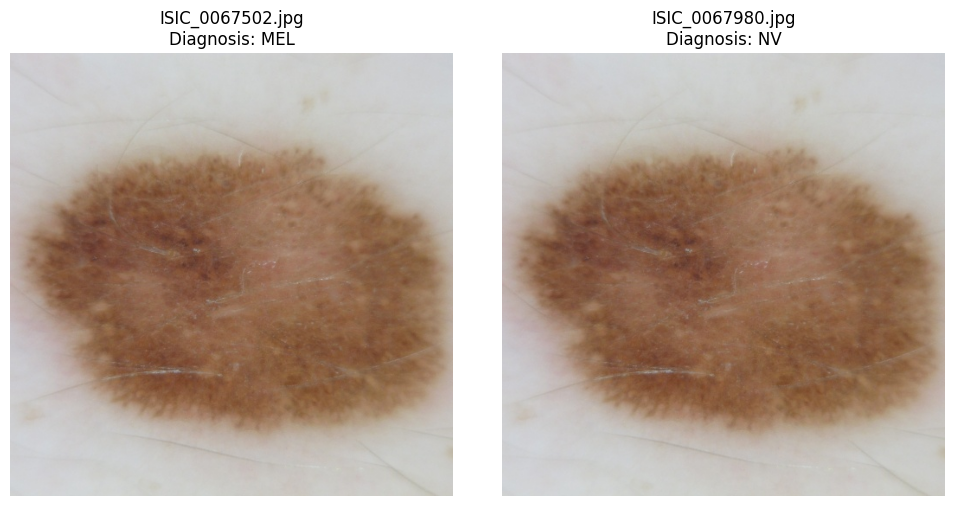


=== Conflicting Group 2 ===


,filename,image_name,diagnosis,patient_id
0,ISIC_0069013.jpg,ISIC_0069013,NV,-1
1,ISIC_0071017.jpg,ISIC_0071017,MEL,-1


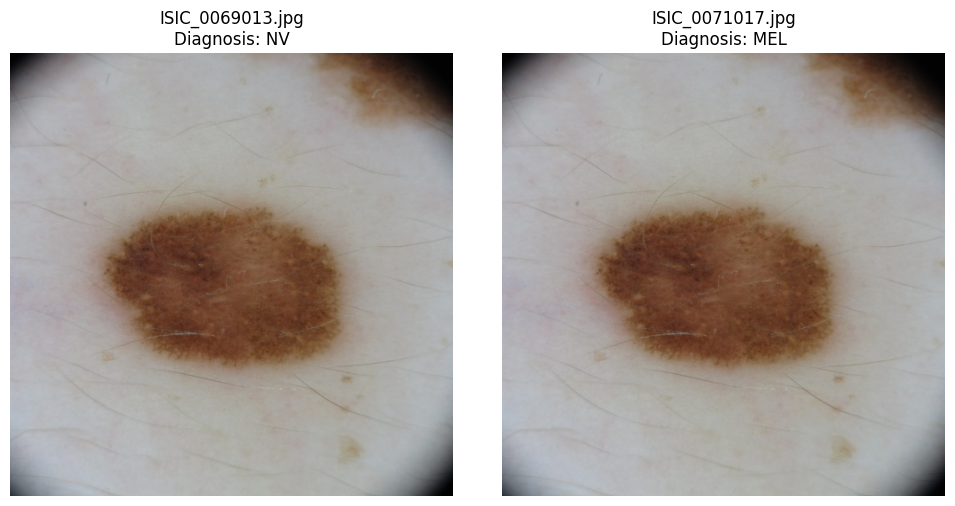

In [10]:
from PIL import Image
from IPython.display import display
import matplotlib.pyplot as plt

# Find hashes associated with more than one diagnosis
conflicting_hashes = (
    duplicate_report.groupby("file_hash")["diagnosis"]
    .nunique()
)

conflicting_hashes = conflicting_hashes[
    conflicting_hashes > 1
].index.tolist()

print("Number of conflicting groups:", len(conflicting_hashes))

for i, file_hash in enumerate(conflicting_hashes, start=1):
    group = duplicate_report[
        duplicate_report["file_hash"] == file_hash
    ]

    print(f"\n=== Conflicting Group {i} ===")
    display(
        group[["filename", "image_name", "diagnosis", "patient_id"]]
        .reset_index(drop=True)
    )

    # Show the identical files side by side
    filenames = group["filename"].tolist()

    fig, axes = plt.subplots(
        1, len(filenames),
        figsize=(5 * len(filenames), 5)
    )

    if len(filenames) == 1:
        axes = [axes]

    for ax, filename in zip(axes, filenames):
        image_path = IMAGE_DIR / filename

        with Image.open(image_path) as img:
            ax.imshow(img.copy())

        diagnosis = group.loc[
            group["filename"] == filename, "diagnosis"
        ].iloc[0]

        ax.set_title(f"{filename}\nDiagnosis: {diagnosis}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()

In [11]:
for file_hash in conflicting_hashes:
    group = duplicate_report[
        duplicate_report["file_hash"] == file_hash
    ]

    print("\nDuplicate group:")
    print(
        group[["filename", "image_name", "diagnosis"]]
        .to_string(index=False)
    )


Duplicate group:
        filename   image_name diagnosis
ISIC_0067502.jpg ISIC_0067502       MEL
ISIC_0067980.jpg ISIC_0067980        NV

Duplicate group:
        filename   image_name diagnosis
ISIC_0069013.jpg ISIC_0069013        NV
ISIC_0071017.jpg ISIC_0071017       MEL


In [12]:
# Image names from the two conflicting duplicate groups
conflicting_images = [
    "ISIC_0067502",
    "ISIC_0067980",
    "ISIC_0069013",
    "ISIC_0071017"
]

# Create a cleaned metadata dataframe
df_clean = df[
    ~df["image_name"].isin(conflicting_images)
].copy()

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Excluded rows:", len(df) - len(df_clean))

Original rows: 25331
Cleaned rows: 25327
Excluded rows: 4


In [13]:
# Identify duplicate groups with conflicting labels
conflict_hashes = set(conflicting_hashes)

# Keep only the non-conflicting duplicate groups
safe_duplicates = duplicate_report[
    ~duplicate_report["file_hash"].isin(conflict_hashes)
].copy()

# Choose one canonical file per exact-duplicate group
# Keep the first filename alphabetically
duplicate_files_to_exclude = set()

for file_hash, group in safe_duplicates.groupby("file_hash"):
    filenames = sorted(group["filename"].unique())
    duplicate_files_to_exclude.update(filenames[1:])

# Create deduplicated metadata without deleting original files
df_dedup = df_clean[
    ~df_clean["matched_filename"].isin(duplicate_files_to_exclude)
].copy()

print("Original images:", len(df))
print("After excluding conflicting images:", len(df_clean))
print("Exact duplicate copies excluded:", len(duplicate_files_to_exclude))
print("Final rows after deduplication:", len(df_dedup))
print("Remaining duplicate image names:", df_dedup["image_name"].duplicated().sum())

Original images: 25331
After excluding conflicting images: 25327
Exact duplicate copies excluded: 48
Final rows after deduplication: 25279
Remaining duplicate image names: 0


In [14]:
class_report = pd.DataFrame({
    "before": df["diagnosis"].value_counts(),
    "after_cleaning": df_dedup["diagnosis"].value_counts()
}).fillna(0).astype(int)

class_report["removed"] = (
    class_report["before"] - class_report["after_cleaning"]
)

class_report["after_percentage"] = (
    df_dedup["diagnosis"].value_counts(normalize=True) * 100
).round(2)

display(class_report.sort_values("after_cleaning", ascending=False))

,before,after_cleaning,removed,after_percentage
diagnosis,,,,
NV,12875,12862,13,50.88
MEL,4522,4512,10,17.85
BCC,3323,3316,7,13.12
BKL,2624,2610,14,10.32
AK,867,859,8,3.40
SCC,628,628,0,2.48
VASC,253,253,0,1.00
DF,239,239,0,0.95


In [15]:
import pandas as pd

# 1. Missing values
missing_report = pd.DataFrame({
    "missing_count": df_dedup.isna().sum(),
    "missing_percentage": (
        df_dedup.isna().mean() * 100
    ).round(2)
})

print("=== Missing Values ===")
display(
    missing_report[missing_report["missing_count"] > 0]
    .sort_values("missing_count", ascending=False)
)

# 2. Check categorical metadata
for col in [
    "diagnosis",
    "benign_malignant",
    "sex",
    "anatom_site_general_challenge"
]:
    print(f"\n=== {col} ===")
    display(df_dedup[col].value_counts(dropna=False))

# 3. Check age values
print("\n=== Age Summary ===")
display(df_dedup["age_approx"].describe())

print("Age values below 0:",
      (df_dedup["age_approx"] < 0).sum())

print("Age values above 100:",
      (df_dedup["age_approx"] > 100).sum())

# 4. Verify diagnosis-label consistency
print("\n=== Diagnosis vs Benign/Malignant ===")
display(pd.crosstab(
    df_dedup["diagnosis"],
    df_dedup["benign_malignant"],
    dropna=False
))

# 5. Verify that exact duplicate files are gone
print("\n=== Final Duplicate Verification ===")
print(
    "Remaining exact duplicate groups:",
    sum(
        len(files) > 1
        for files in hash_to_images.values()
        if not set(files) & duplicate_files_to_exclude
    )
)

=== Missing Values ===


,missing_count,missing_percentage
anatom_site_general_challenge,2616,10.35
age_approx,432,1.71



=== diagnosis ===


diagnosis
NV      12862
MEL      4512
BCC      3316
BKL      2610
AK        859
SCC       628
VASC      253
DF        239
Name: count, dtype: int64


=== benign_malignant ===


...


=== Age Summary ===


count    24847.000000
mean        54.003904
std         18.123498
min          0.000000
25%         40.000000
50%         55.000000
75%         70.000000
max         85.000000
Name: age_approx, dtype: float64

Age values below 0: 0
Age values above 100: 0

=== Diagnosis vs Benign/Malignant ===


benign_malignant,benign,malignant
diagnosis,,
AK,859,0
BCC,3316,0
BKL,2610,0
DF,239,0
MEL,0,4512
NV,12862,0
SCC,628,0
VASC,253,0



=== Final Duplicate Verification ===
Remaining exact duplicate groups: 2


In [16]:
import hashlib
from collections import defaultdict
from tqdm.auto import tqdm

# Recalculate hashes using only images retained in df_dedup
final_hash_groups = defaultdict(list)

for filename in tqdm(
    df_dedup["matched_filename"].unique(),
    desc="Final duplicate verification"
):
    image_path = IMAGE_DIR / filename

    with open(image_path, "rb") as f:
        file_hash = hashlib.sha256(f.read()).hexdigest()

    final_hash_groups[file_hash].append(filename)

remaining_duplicates = {
    h: files
    for h, files in final_hash_groups.items()
    if len(files) > 1
}

print("Rows in cleaned metadata:", len(df_dedup))
print("Unique image files:", df_dedup["matched_filename"].nunique())
print("Remaining exact duplicate groups:", len(remaining_duplicates))
print(
    "Images in remaining duplicate groups:",
    sum(len(files) for files in remaining_duplicates.values())
)

if remaining_duplicates:
    for files in remaining_duplicates.values():
        print(files)

Final duplicate verification:   0%|          | 0/25279 [00:00<?, ?it/s]

Rows in cleaned metadata: 25279
Unique image files: 25279
Remaining exact duplicate groups: 0
Images in remaining duplicate groups: 0


In [17]:

from pathlib import Path
from collections import defaultdict
import hashlib
import pandas as pd
import zipfile

# ==========================================
# 1. Output folder
# ==========================================
OUTPUT_DIR = Path("/content/isic_preprocessing_output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ==========================================
# 2. Verify the cleaned dataset
# ==========================================
final_hash_groups = defaultdict(list)

for filename in df_dedup["matched_filename"].unique():
    image_path = IMAGE_DIR / filename

    with open(image_path, "rb") as f:
        file_hash = hashlib.sha256(f.read()).hexdigest()

    final_hash_groups[file_hash].append(filename)

remaining_duplicates = {
    h: files for h, files in final_hash_groups.items()
    if len(files) > 1
}

assert len(df_dedup) == df_dedup["matched_filename"].nunique(), (
    "Duplicate filenames found in cleaned metadata."
)
assert not remaining_duplicates, (
    "Exact duplicates remain. Review them before exporting."
)

# ==========================================
# 3. Save cleaned metadata
# ==========================================
df_dedup.to_csv(
    OUTPUT_DIR / "cleaned_metadata.csv",
    index=False
)

# ==========================================
# 4. Create an exclusion log
# ==========================================
conflict_set = set(conflicting_images)
duplicate_exclusion_set = set(duplicate_files_to_exclude)

excluded = df[
    df["image_name"].isin(conflict_set)
    | df["matched_filename"].isin(duplicate_exclusion_set)
].copy()

excluded["exclusion_reason"] = excluded.apply(
    lambda row: (
        "Conflicting diagnosis for exact duplicate image"
        if row["image_name"] in conflict_set
        else "Extra copy of exact duplicate image"
    ),
    axis=1
)

excluded.to_csv(
    OUTPUT_DIR / "excluded_records.csv",
    index=False
)

# ==========================================
# 5. Class distribution before and after
# ==========================================
before_counts = df["diagnosis"].value_counts()
after_counts = df_dedup["diagnosis"].value_counts()

class_distribution = pd.DataFrame({
    "count_before": before_counts,
    "count_after": after_counts
}).fillna(0).astype(int)

class_distribution["removed"] = (
    class_distribution["count_before"]
    - class_distribution["count_after"]
)

class_distribution["percentage_after"] = (
    class_distribution["count_after"]
    / len(df_dedup) * 100
).round(2)

class_distribution.index.name = "diagnosis"

class_distribution.to_csv(
    OUTPUT_DIR / "class_distribution.csv"
)

# ==========================================
# 6. Missing values report
# ==========================================
missing_report = pd.DataFrame({
    "missing_count": df_dedup.isna().sum(),
    "missing_percentage": (
        df_dedup.isna().mean() * 100
    ).round(2)
})

missing_report.index.name = "column"

missing_report.to_csv(
    OUTPUT_DIR / "missing_values.csv"
)

# ==========================================
# 7. Write preprocessing report
# ==========================================
report = f"""
ISIC 2019 Preprocessing Report
==============================

Dataset overview
----------------
Original metadata rows: {len(df)}
Cleaned metadata rows: {len(df_dedup)}
Excluded rows: {len(excluded)}
Unique retained image files: {df_dedup['matched_filename'].nunique()}

Image quality checks
--------------------
Images checked: {len(image_report)}
Corrupted images found: {(image_report['status'] != 'OK').sum()}
Image dimensions observed: 512 x 512
Image format observed: JPEG
Image color mode observed: RGB
Missing image files during initial matching: 0

Duplicate checks
----------------
Exact duplicate groups found initially: {len(duplicate_groups)}
Conflicting duplicate groups: {len(conflicting_hashes)}
Rows excluded due to conflicting labels: {len(conflict_set)}
Extra duplicate copies excluded: {len(duplicate_exclusion_set)}
Exact duplicate groups remaining: {len(remaining_duplicates)}

Metadata notes
--------------
Missing age_approx values: {df_dedup['age_approx'].isna().sum()}
Missing anatomical site values: {
    df_dedup['anatom_site_general_challenge'].isna().sum()
}
Unknown patient IDs (-1): {(df_dedup['patient_id'] == -1).sum()}

Limitations and cautions
------------------------
1. Patient-level splitting cannot be reliably performed using patient_id
   because all patient_id values are -1 in this dataset version.
2. SHA-256 detects byte-identical files only. Near-duplicate images have
   not been checked by this procedure.
3. Missing metadata values were not used as a reason to delete images.
4. No augmentation, synthetic image generation, or class balancing
   was performed.
5. Conflicting-label duplicate groups were excluded because the correct
   diagnosis could not be verified from the available metadata.
6. The diagnosis labels have not been independently clinically validated.

Recommended next steps
---------------------
1. Review near-duplicate images if feasible.
2. Agree with the modeling teammate on the target task and data split.
3. Perform augmentation or sampling on the training split only.
4. Evaluate per-class precision, recall, F1-score, and confusion matrix.
"""

(OUTPUT_DIR / "preprocessing_report.txt").write_text(
    report.strip(),
    encoding="utf-8"
)

# ==========================================
# 8. Bundle all deliverables into a ZIP
# ==========================================
zip_path = Path("/content/isic_preprocessing_deliverables.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for file_path in OUTPUT_DIR.iterdir():
        if file_path.is_file():
            zf.write(file_path, arcname=file_path.name)

print("Preprocessing deliverables created successfully.")
print("Cleaned rows:", len(df_dedup))
print("Excluded rows:", len(excluded))
print("Remaining exact duplicate groups:", len(remaining_duplicates))
print("\nFiles:")
for file_path in sorted(OUTPUT_DIR.iterdir()):
    print("-", file_path.name)

print("\nZIP:", zip_path)


Preprocessing deliverables created successfully.
Cleaned rows: 25279
Excluded rows: 52
Remaining exact duplicate groups: 0

Files:
- class_distribution.csv
- cleaned_metadata.csv
- excluded_records.csv
- missing_values.csv
- preprocessing_report.txt

ZIP: /content/isic_preprocessing_deliverables.zip


In [18]:
# Save a stable manifest for the merge audit
isic_clean = df_dedup.copy()

isic_clean["source"] = "ISIC2019"
isic_clean["sha256"] = isic_clean["matched_filename"].map(
    lambda filename: hashlib.sha256(
        (IMAGE_DIR / filename).read_bytes()
    ).hexdigest()
)

isic_clean.to_csv(
    OUTPUT_DIR / "isic_clean_manifest.csv",
    index=False
)

print("Clean ISIC records:", len(isic_clean))
print("Unique image hashes:", isic_clean["sha256"].nunique())
print("Saved:", OUTPUT_DIR / "isic_clean_manifest.csv")

Clean ISIC records: 25279
Unique image hashes: 25279
Saved: /content/isic_preprocessing_output/isic_clean_manifest.csv


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [20]:
from pathlib import Path

print("Current directory:", Path.cwd())

# عرض الملفات الموجودة في المجلد الحالي
print(list(Path.cwd().iterdir())[:20])

Current directory: /kaggle/working
[PosixPath('/kaggle/working/.virtual_documents')]


In [21]:
isic_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 25279 entries, 0 to 25330
Data columns (total 14 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   image_name                     25279 non-null  object 
 1   patient_id                     25279 non-null  int64  
 2   sex                            25279 non-null  object 
 3   age_approx                     24847 non-null  float64
 4   anatom_site_general_challenge  22663 non-null  object 
 5   diagnosis                      25279 non-null  object 
 6   benign_malignant               25279 non-null  object 
 7   target                         25279 non-null  int64  
 8   tfrecord                       25279 non-null  int64  
 9   width                          25279 non-null  int64  
 10  height                         25279 non-null  int64  
 11  matched_filename               25279 non-null  object 
 12  source                         25279 non-null  obje

In [22]:
isic_df=isic_clean.copy()
isic_df.head()

column,image_name,patient_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target,tfrecord,width,height,matched_filename,source,sha256
0,ISIC_0000000,-1,female,55.0,anterior torso,NV,benign,0,4,1022,767,ISIC_0000000.jpg,ISIC2019,523803f6ed94a31cf72465ce684d2488871a059b39a7a7...
1,ISIC_0000001,-1,female,30.0,anterior torso,NV,benign,0,18,1022,767,ISIC_0000001.jpg,ISIC2019,b41bbbb414bebc7e90501d90d7941726291f4e46bba3c7...
2,ISIC_0000002,-1,female,60.0,upper extremity,MEL,malignant,1,0,1022,767,ISIC_0000002.jpg,ISIC2019,fc30b8a43cc0ae238fcaba71155d831dfb86e9eb2ccc57...
3,ISIC_0000003,-1,male,30.0,upper extremity,NV,benign,0,24,1022,767,ISIC_0000003.jpg,ISIC2019,a0c299a2163178b468f8d7ca6c66b8b73c70533f7f1654...
4,ISIC_0000004,-1,male,80.0,posterior torso,MEL,malignant,1,14,1022,767,ISIC_0000004.jpg,ISIC2019,1fe6ec92526cf04b67cd5493606922a60faf7104a1a144...


#download ham 10000

##**HAM10000**

In [23]:
!pip -q install kagglehub

In [24]:
import kagglehub
from pathlib import Path

HAM_ROOT = Path(
    kagglehub.dataset_download(
        "kmader/skin-cancer-mnist-ham10000"
    )
)

print("HAM dataset path:", HAM_ROOT)

metadata_files = list(
    HAM_ROOT.rglob("HAM10000_metadata.csv")
)

if not metadata_files:
    raise FileNotFoundError(
        "HAM10000_metadata.csv was not found."
    )

HAM_CSV = metadata_files[0]
ham_df = pd.read_csv(HAM_CSV)

print("HAM shape:", ham_df.shape)
print("Columns:", ham_df.columns.tolist())

display(ham_df.head())

HAM dataset path: /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000
HAM shape: (10015, 7)
Columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [25]:
HAM_IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

ham_image_index = {}

for path in HAM_ROOT.rglob("*"):
    if (
        path.is_file()
        and path.suffix.lower() in HAM_IMAGE_EXTENSIONS
    ):
        ham_image_index.setdefault(path.stem, []).append(path)

ham_meta = ham_df.copy()

ham_meta["image_path"] = ham_meta["image_id"].map(
    lambda image_id: (
        str(ham_image_index[image_id][0])
        if len(ham_image_index.get(image_id, [])) == 1
        else None
    )
)

ham_meta["path_match_count"] = ham_meta["image_id"].map(
    lambda image_id: len(ham_image_index.get(image_id, []))
)

print("HAM metadata rows:", len(ham_meta))
print("Images matched:", ham_meta["path_match_count"].eq(1).sum())
print("Missing/ambiguous matches:",
      ham_meta["path_match_count"].ne(1).sum())

display(
    ham_meta.loc[
        ham_meta["path_match_count"].ne(1),
        ["image_id", "dx", "path_match_count"]
    ].head(10)
)

HAM metadata rows: 10015
Images matched: 0
Missing/ambiguous matches: 10015


,image_id,dx,path_match_count
0,ISIC_0027419,bkl,2
1,ISIC_0025030,bkl,2
2,ISIC_0026769,bkl,2
3,ISIC_0025661,bkl,2
4,ISIC_0031633,bkl,2
5,ISIC_0027850,bkl,2
6,ISIC_0029176,bkl,2
7,ISIC_0029068,bkl,2
8,ISIC_0025837,bkl,2
9,ISIC_0025209,bkl,2


In [26]:
from pathlib import Path
from collections import defaultdict
import pandas as pd

# 1. Index all image files by filename stem
ham_image_index = defaultdict(list)

for p in HAM_ROOT.rglob("*"):
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}:
        ham_image_index[p.stem].append(p)

# 2. Choose one path per image ID deterministically
def choose_image_path(image_id):
    matches = ham_image_index.get(image_id, [])

    if not matches:
        return None

    # Prefer the standard Kaggle folder name when available
    preferred = [
        p for p in matches
        if p.parent.name == "HAM10000_images_part_1"
    ]

    chosen = preferred[0] if preferred else sorted(matches)[0]
    return str(chosen)

ham_df["image_path"] = ham_df["image_id"].map(choose_image_path)

# 3. Check matching results
matched_count = ham_df["image_path"].notna().sum()
missing_count = ham_df["image_path"].isna().sum()

print("HAM metadata rows:", len(ham_df))
print("Images matched:", matched_count)
print("Missing images:", missing_count)
print("Unique matched image IDs:", ham_df["image_path"].dropna().map(
    lambda p: Path(p).stem
).nunique())

display(
    ham_df[["image_id", "dx", "image_path"]].head(10)
)

HAM metadata rows: 10015
Images matched: 10015
Missing images: 0
Unique matched image IDs: 10015


,image_id,dx,image_path
0,ISIC_0027419,bkl,/kaggle/input/datasets/kmader/skin-cancer-mnis...
1,ISIC_0025030,bkl,/kaggle/input/datasets/kmader/skin-cancer-mnis...
2,ISIC_0026769,bkl,/kaggle/input/datasets/kmader/skin-cancer-mnis...
3,ISIC_0025661,bkl,/kaggle/input/datasets/kmader/skin-cancer-mnis...
4,ISIC_0031633,bkl,/kaggle/input/datasets/kmader/skin-cancer-mnis...
5,ISIC_0027850,bkl,/kaggle/input/datasets/kmader/skin-cancer-mnis...
6,ISIC_0029176,bkl,/kaggle/input/datasets/kmader/skin-cancer-mnis...
7,ISIC_0029068,bkl,/kaggle/input/datasets/kmader/skin-cancer-mnis...
8,ISIC_0025837,bkl,/kaggle/input/datasets/kmader/skin-cancer-mnis...
9,ISIC_0025209,bkl,/kaggle/input/datasets/kmader/skin-cancer-mnis...


In [27]:
import hashlib
from pathlib import Path

def get_sha256(path):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)

    return h.hexdigest()


# 1. SHA256 for HAM10000
ham_df["sha256"] = ham_df["image_path"].map(get_sha256)

print("HAM rows:", len(ham_df))
print("HAM unique hashes:", ham_df["sha256"].nunique())
print("HAM duplicate hashes:", ham_df["sha256"].duplicated().sum())


# 2. Compare against the cleaned ISIC dataset
isic_hashes = set(isic_clean["sha256"])
ham_hashes = set(ham_df["sha256"])

common_hashes = isic_hashes & ham_hashes

print("ISIC unique hashes:", len(isic_hashes))
print("HAM unique hashes:", len(ham_hashes))
print("Exact hashes shared between datasets:", len(common_hashes))

HAM rows: 10015
HAM unique hashes: 10013
HAM duplicate hashes: 2
ISIC unique hashes: 25279
HAM unique hashes: 10013
Exact hashes shared between datasets: 0


In [28]:
# Find all rows whose image hash is duplicated
ham_duplicates = ham_df[
    ham_df["sha256"].duplicated(keep=False)
].sort_values("sha256")

display(
    ham_duplicates[
        ["image_id", "dx", "lesion_id", "sha256", "image_path"]
    ]
)

print("Rows involved in duplicate groups:", len(ham_duplicates))
print("Duplicate hash groups:", ham_duplicates["sha256"].nunique())

,image_id,dx,lesion_id,sha256,image_path
8303,ISIC_0029938,nv,HAM_0001895,b1780747e0ccd3d31652bcf942a0f4bb22af6e058a5dc8...,/kaggle/input/datasets/kmader/skin-cancer-mnis...
8304,ISIC_0024777,nv,HAM_0001895,b1780747e0ccd3d31652bcf942a0f4bb22af6e058a5dc8...,/kaggle/input/datasets/kmader/skin-cancer-mnis...
8260,ISIC_0029861,nv,HAM_0002300,b8b37d24e294c5182a1884741c109d8b3bc58edaa993e8...,/kaggle/input/datasets/kmader/skin-cancer-mnis...
8261,ISIC_0024366,nv,HAM_0002300,b8b37d24e294c5182a1884741c109d8b3bc58edaa993e8...,/kaggle/input/datasets/kmader/skin-cancer-mnis...


Rows involved in duplicate groups: 4
Duplicate hash groups: 2


In [29]:
# Keep one record per exact image hash
ham_clean = (
    ham_df
    .sort_values("image_id")
    .drop_duplicates(subset="sha256", keep="first")
    .copy()
)

print("Original rows:", len(ham_df))
print("Clean rows:", len(ham_clean))
print("Removed exact duplicate records:", len(ham_df) - len(ham_clean))
print("Unique hashes after cleaning:", ham_clean["sha256"].nunique())
print("Missing image paths:", ham_clean["image_path"].isna().sum())

Original rows: 10015
Clean rows: 10013
Removed exact duplicate records: 2
Unique hashes after cleaning: 10013
Missing image paths: 0


In [30]:
# ابدئي من نسخة ISIC الأصلية
isic_part = isic_clean.copy()

isic_part["diagnosis"] = (
    isic_part["diagnosis"]
    .astype("string")
    .str.strip()
    .str.lower()
)

# عدد صور NV المطلوب
NV_SAMPLES = 2500
SEED = 42

isic_nv = isic_part[isic_part["diagnosis"] == "nv"].copy()
isic_other = isic_part[isic_part["diagnosis"] != "nv"].copy()

if len(isic_nv) < NV_SAMPLES:
    raise ValueError(f"Only {len(isic_nv)} NV images available.")

isic_nv_sampled = isic_nv.sample(
    n=NV_SAMPLES,
    random_state=SEED
)

isic_part = pd.concat(
    [isic_other, isic_nv_sampled],
    ignore_index=True
)

print("ISIC NV after sampling:",
      (isic_part["diagnosis"] == "nv").sum())

ISIC NV after sampling: 2500


In [31]:
import pandas as pd

# Count from the sampled ISIC data and the full HAM data
isic_counts = isic_part["diagnosis"].value_counts()
ham_counts = ham_df["dx"].value_counts()

# Compare class distributions
class_comparison = pd.concat(
    [
        isic_counts.rename("ISIC2019"),
        ham_counts.rename("HAM10000")
    ],
    axis=1
).fillna(0).astype(int)

class_comparison["Combined"] = (
    class_comparison["ISIC2019"]
    + class_comparison["HAM10000"]
)

class_comparison["Percentage"] = (
    class_comparison["Combined"]
    / class_comparison["Combined"].sum()
    * 100
)

display(
    class_comparison.sort_values(
        "Combined", ascending=False
    ).round(2)
)

print("Total images:", class_comparison["Combined"].sum())

print(
    "ISIC NV:",
    (isic_part["diagnosis"] == "nv").sum()
)

print(
    "HAM NV:",
    (ham_df["dx"] == "nv").sum()
)

,ISIC2019,HAM10000,Combined,Percentage
nv,2500,6705,9205,36.92
mel,4512,1113,5625,22.56
bcc,3316,514,3830,15.36
bkl,2610,1099,3709,14.88
ak,859,0,859,3.45
scc,628,0,628,2.52
vasc,253,142,395,1.58
df,239,115,354,1.42
akiec,0,327,327,1.31


Total images: 24932
ISIC NV: 2500
HAM NV: 6705


In [32]:
print("ISIC columns:")
print(isic_clean.columns.tolist())

print("\nHAM columns:")
print(ham_clean.columns.tolist())

ISIC columns:
['image_name', 'patient_id', 'sex', 'age_approx', 'anatom_site_general_challenge', 'diagnosis', 'benign_malignant', 'target', 'tfrecord', 'width', 'height', 'matched_filename', 'source', 'sha256']

HAM columns:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'image_path', 'sha256']


In [33]:
from pathlib import Path

# Add image paths to BOTH dataframes.
# isic_part was sampled in cell 31, so updating isic_clean alone is not enough.
isic_clean["image_path"] = isic_clean["matched_filename"].map(
    lambda filename: str(IMAGE_DIR / filename)
)
isic_part["image_path"] = isic_part["matched_filename"].map(
    lambda filename: str(IMAGE_DIR / filename)
)

# Verify the selected ISIC files and all retained HAM files exist.
isic_missing = sum(
    not Path(p).is_file()
    for p in isic_part["image_path"].dropna()
)
ham_missing = sum(
    not Path(p).is_file()
    for p in ham_clean["image_path"].dropna()
)

print("Selected ISIC rows:", len(isic_part))
print("ISIC missing paths:", isic_part["image_path"].isna().sum())
print("ISIC missing files:", isic_missing)
print("HAM rows after exact-duplicate removal:", len(ham_clean))
print("HAM missing files:", ham_missing)

assert isic_part["image_path"].notna().all(), "ISIC image_path contains missing values."
assert ham_clean["image_path"].notna().all(), "HAM image_path contains missing values."
assert isic_missing == 0, "Some selected ISIC image files were not found."
assert ham_missing == 0, "Some HAM image files were not found."


Selected ISIC rows: 14917
ISIC missing paths: 0
ISIC missing files: 0
HAM rows after exact-duplicate removal: 10013
HAM missing files: 0


### Fix: preserve the sampled ISIC image paths\nThe ISIC sample (`isic_part`) is created before image paths are attached to `isic_clean`. The merge now explicitly creates `image_path` on `isic_part` before concatenation. The assertions below stop the notebook if ISIC rows are silently dropped.\n

In [34]:

import pandas as pd

# =========================================
# 1. تجهيز ISIC 2019 مع الاحتفاظ بكل الفئات
# =========================================
# 1. تجهيز ISIC باستخدام العينة اللي اتعملت بالفعل
# ممنوع نرجع نعمل isic_clean.copy() هنا

isic_part = isic_part.copy()

# Defensive fix: recreate paths here too, so this cell works even if cell 34
# was run before/after sampling or the notebook kernel was restarted.
isic_part["image_path"] = isic_part["matched_filename"].map(
    lambda filename: str(IMAGE_DIR / filename)
)

assert isic_part["image_path"].notna().all()
assert isic_part["image_path"].map(lambda p: Path(p).is_file()).all(), (
    "At least one selected ISIC image path does not exist."
)

isic_part["diagnosis"] = (
    isic_part["diagnosis"]
    .astype("string")
    .str.strip()
    .str.lower()
)

isic_part["source"] = "ISIC2019"

# الاحتفاظ بـ lesion_id لو موجود، وإلا نستخدم معرف صورة مستقل
if "lesion_id" in isic_part.columns:
    isic_lesion = isic_part["lesion_id"].astype("string").str.strip()
    valid_lesion = isic_lesion.notna() & isic_lesion.ne("")
    isic_part["lesion_id"] = isic_lesion.where(valid_lesion, pd.NA)
else:
    isic_part["lesion_id"] = pd.NA

isic_image_id = isic_part["matched_filename"].astype("string")

isic_part["group_id"] = (
    "ISIC_IMAGE_" + isic_image_id
)

valid_lesion = isic_part["lesion_id"].notna()

isic_part.loc[valid_lesion, "group_id"] = (
    "ISIC_LESION_" + isic_part.loc[valid_lesion, "lesion_id"]
)
# =========================================
# 2. تجهيز HAM10000 مع الاحتفاظ بكل الفئات
# =========================================

ham_part = ham_clean.copy()

ham_part["diagnosis"] = (
    ham_part["dx"]
    .astype("string")
    .str.strip()
    .str.lower()
)

ham_part["source"] = "HAM10000"

ham_part["lesion_id"] = (
    ham_part["lesion_id"].astype("string").str.strip()
)

valid_ham_lesion = (
    ham_part["lesion_id"].notna()
    & ham_part["lesion_id"].ne("")
)

# كل صور الآفة الواحدة لها نفس group_id
ham_part["group_id"] = pd.NA

ham_part.loc[valid_ham_lesion, "group_id"] = (
    "HAM_LESION_" + ham_part.loc[valid_ham_lesion, "lesion_id"]
)

# الصور التي ليس لها lesion_id تحتاج معرفًا مستقلًا
missing_ham_lesion = ~valid_ham_lesion

ham_part.loc[missing_ham_lesion, "group_id"] = (
    "HAM_IMAGE_"
    + ham_part.loc[missing_ham_lesion, "image_path"].astype("string")
)

# =========================================
# 3. توحيد الأعمدة من غير استبعاد أي فئة
# =========================================

columns_to_keep = [
    "image_path",
    "diagnosis",
    "source",
    "sha256",
    "lesion_id",
    "group_id",
    'sex',
    'age_approx',
    'anatom_site_general_challenge'
]
# التأكد من وجود الأعمدة المطلوبة
for col in columns_to_keep:
    if col not in isic_part.columns:
        isic_part[col] = pd.NA
    if col not in ham_part.columns:
        ham_part[col] = pd.NA

combined_df = pd.concat(
    [
        isic_part[columns_to_keep],
        ham_part[columns_to_keep]
    ],
    ignore_index=True
)

# استبعاد الصفوف التي لا تحتوي على Label أو مسار صورة
rows_before_drop = len(combined_df)
combined_df = combined_df.dropna(
    subset=["image_path", "diagnosis"]
).copy()
rows_dropped = rows_before_drop - len(combined_df)

print("Rows dropped for missing image_path/diagnosis:", rows_dropped)
print("ISIC rows entering merge:", len(isic_part))
print("HAM rows entering merge:", len(ham_part))
print("Expected merged rows:", len(isic_part) + len(ham_part))
print("Actual merged rows:", len(combined_df))

# If this fails, do not continue to splitting/training.
assert rows_dropped == 0, "Rows were dropped because image_path or diagnosis is missing."
assert len(combined_df) == len(isic_part) + len(ham_part), (
    "Merged row count does not match the sum of the two input dataframes."
)
assert (combined_df["source"] == "ISIC2019").sum() == len(isic_part)
assert (combined_df["source"] == "HAM10000").sum() == len(ham_part)

# =========================================
# 4. فحوصات الدمج
# =========================================


# 1. فحوصات الدمج
print("Total images:", len(combined_df))
print("Unique classes:", combined_df["diagnosis"].nunique())
print("Missing image paths:", combined_df["image_path"].isna().sum())
print("Missing diagnoses:", combined_df["diagnosis"].isna().sum())
print("Missing group IDs:", combined_df["group_id"].isna().sum())

# 2. التأكد من عدد NV في كل مصدر
print("\nISIC NV:", (isic_part["diagnosis"] == "nv").sum())
print("HAM NV:", (ham_part["diagnosis"] == "nv").sum())
print("Combined NV:", (combined_df["diagnosis"] == "nv").sum())

# 3. عدد الصور في كل فئة حسب المصدر
print("\nClasses per source:")
display(
    pd.crosstab(
        combined_df["diagnosis"],
        combined_df["source"],
        margins=True
    )
)

# 4. عدد الصور ونسبتها في كل فئة
print("\nImages per class:")
class_counts = combined_df["diagnosis"].value_counts()

class_summary = pd.DataFrame({
    "image_count": class_counts,
    "percentage": (
        combined_df["diagnosis"].value_counts(normalize=True) * 100
    ).round(2)
})

display(class_summary)

# 5. عدد الصور لكل Lesion في HAM
print("\nHAM images per lesion:")
display(
    ham_part.loc[valid_ham_lesion]
    .groupby("lesion_id")
    .size()
    .value_counts()
    .sort_index()
    .rename_axis("images_per_lesion")
    .to_frame("number_of_lesions")
)


Rows dropped for missing image_path/diagnosis: 0
ISIC rows entering merge: 14917
HAM rows entering merge: 10013
Expected merged rows: 24930
Actual merged rows: 24930
Total images: 24930
Unique classes: 9
Missing image paths: 0
Missing diagnoses: 0
Missing group IDs: 0

ISIC NV: 2500
HAM NV: 6703
Combined NV: 9203

Classes per source:


/tmp/ipykernel_48/1359954943.py:111: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined_df = pd.concat(


source,HAM10000,ISIC2019,All
diagnosis,,,
ak,0,859,859
akiec,327,0,327
bcc,514,3316,3830
bkl,1099,2610,3709
df,115,239,354
mel,1113,4512,5625
nv,6703,2500,9203
scc,0,628,628
vasc,142,253,395



Images per class:


,image_count,percentage
diagnosis,,
nv,9203,36.92
mel,5625,22.56
bcc,3830,15.36
bkl,3709,14.88
ak,859,3.45
scc,628,2.52
vasc,395,1.58
df,354,1.42
akiec,327,1.31



HAM images per lesion:


,number_of_lesions
images_per_lesion,
1,5514
2,1425
3,488
4,34
5,5
6,4


In [35]:
print(combined_df.columns.tolist())

['image_path', 'diagnosis', 'source', 'sha256', 'lesion_id', 'group_id', 'sex', 'age_approx', 'anatom_site_general_challenge']


# to merge other columns

In [36]:
import pandas as pd

# 1. Prepare ISIC metadata
isic_meta = isic_part[
    [
        "sha256",
        "image_path",
        "age_approx",
        "sex",
        "anatom_site_general_challenge"
    ]
].copy()

isic_meta = isic_meta.rename(
    columns={"age_approx": "age"}
)

# 2. Prepare HAM metadata
ham_meta = ham_part[
    [
        "sha256",
        "image_path",
        "age",
        "sex",
        "localization"
    ]
].copy()

ham_meta = ham_meta.rename(
    columns={"localization": "anatom_site_general_challenge"}
)

# 3. Combine source metadata
metadata = pd.concat(
    [isic_meta, ham_meta],
    ignore_index=True
)

# 4. Keep one metadata record per image hash
metadata = metadata.drop_duplicates(
    subset="sha256"
)

# 5. Merge with combined_df using sha256
combined_df = combined_df.drop(
    columns=[
        "age", "sex", "age_approx",
        "anatom_site_general_challenge"
    ],
    errors="ignore"
)

combined_df = combined_df.merge(
    metadata.drop(columns="image_path"),
    on="sha256",
    how="left",
    validate="many_to_one"
)

print(combined_df.columns.tolist())
display(combined_df.head())

['image_path', 'diagnosis', 'source', 'sha256', 'lesion_id', 'group_id', 'age', 'sex', 'anatom_site_general_challenge']


,image_path,diagnosis,source,sha256,lesion_id,group_id,age,sex,anatom_site_general_challenge
0,/content/isic/train/ISIC_0000002.jpg,mel,ISIC2019,fc30b8a43cc0ae238fcaba71155d831dfb86e9eb2ccc57...,<NA>,ISIC_IMAGE_ISIC_0000002.jpg,60.0,female,upper extremity
1,/content/isic/train/ISIC_0000004.jpg,mel,ISIC2019,1fe6ec92526cf04b67cd5493606922a60faf7104a1a144...,<NA>,ISIC_IMAGE_ISIC_0000004.jpg,80.0,male,posterior torso
2,/content/isic/train/ISIC_0000013.jpg,mel,ISIC2019,b6a83b742377478ca79a2bb4923114ae78352fbb38b61c...,<NA>,ISIC_IMAGE_ISIC_0000013.jpg,30.0,female,posterior torso
3,/content/isic/train/ISIC_0000022_downsampled.jpg,mel,ISIC2019,61f7243c878a24ac4a717f3f29931dc0c2d6a8cff11844...,<NA>,ISIC_IMAGE_ISIC_0000022_downsampled.jpg,55.0,female,lower extremity
4,/content/isic/train/ISIC_0000026_downsampled.jpg,mel,ISIC2019,05806758b5db7bc44cba270d868c55dc2957581f5a2f0c...,<NA>,ISIC_IMAGE_ISIC_0000026_downsampled.jpg,30.0,female,lower extremity


In [37]:
print(combined_df.groupby("source")["lesion_id"].apply(
    lambda s: s.isna().mean() * 100
))

source
HAM10000      0.0
ISIC2019    100.0
Name: lesion_id, dtype: float64


In [38]:
print("Patient IDs:")
print(isic_part["patient_id"].value_counts(dropna=False).head(10))

print("\nUnique patient IDs excluding -1:")
valid_patients = isic_part.loc[
    isic_part["patient_id"].notna()
    & isic_part["patient_id"].ne(-1),
    "patient_id"
]
print(valid_patients.nunique())

print("\nDuplicate image names:")
print(isic_part["image_name"].duplicated().sum())

Patient IDs:
patient_id
-1    14917
Name: count, dtype: int64

Unique patient IDs excluding -1:
0

Duplicate image names:
0


In [39]:
print("Age missing:", combined_df["age"].isna().sum())
print("Sex missing:", combined_df["sex"].isna().sum())

print(
    "Anatomical site missing:",
    combined_df["anatom_site_general_challenge"].isna().sum()
)

display(
    combined_df[
        ["source", "age", "sex", "anatom_site_general_challenge"]
    ].head(10)
)

Age missing: 245
Sex missing: 0
Anatomical site missing: 957


,source,age,sex,anatom_site_general_challenge
0,ISIC2019,60.0,female,upper extremity
1,ISIC2019,80.0,male,posterior torso
2,ISIC2019,30.0,female,posterior torso
3,ISIC2019,55.0,female,lower extremity
4,ISIC2019,30.0,female,lower extremity
5,ISIC2019,45.0,female,posterior torso
6,ISIC2019,55.0,female,lower extremity
7,ISIC2019,70.0,male,upper extremity
8,ISIC2019,25.0,female,lower extremity
9,ISIC2019,70.0,male,upper extremity


In [40]:
print(combined_df.columns.tolist())

['image_path', 'diagnosis', 'source', 'sha256', 'lesion_id', 'group_id', 'age', 'sex', 'anatom_site_general_challenge']


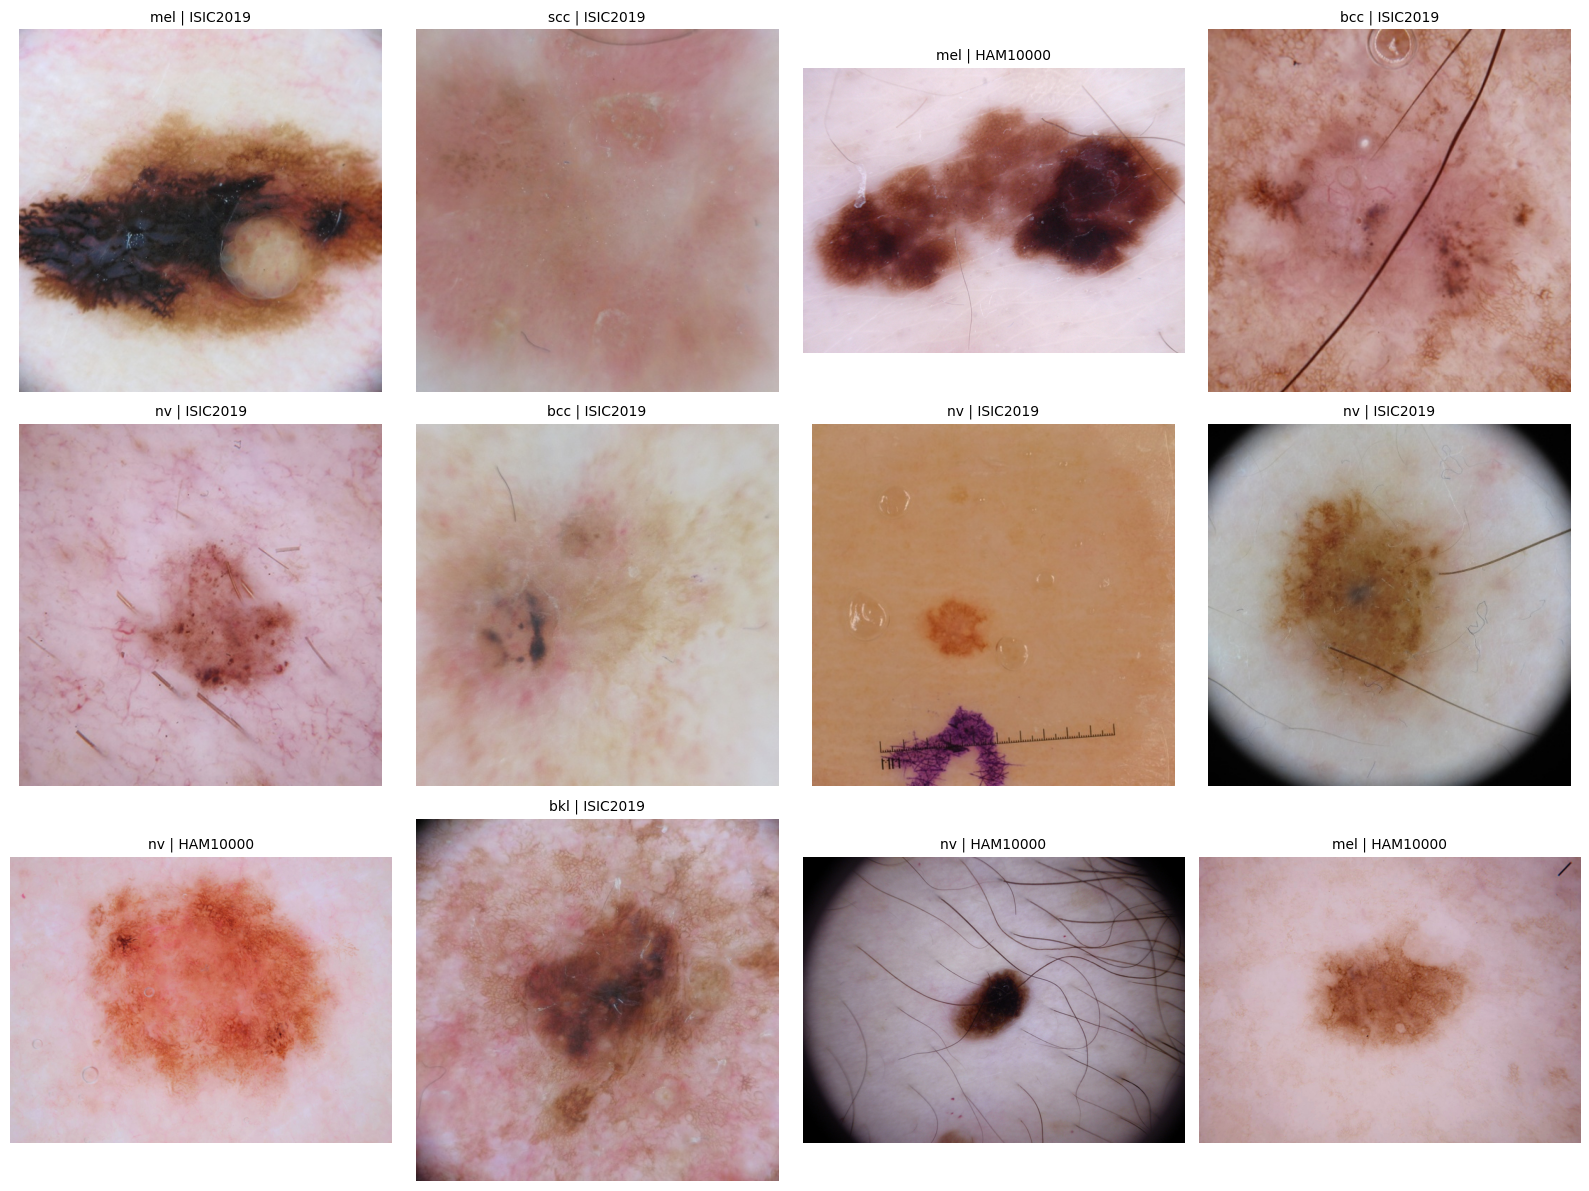

In [41]:
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path
import random

# اختاري 12 صورة عشوائية
sample_df = combined_df.sample(
    n=min(12, len(combined_df)),
    random_state=42
).reset_index(drop=True)

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for i, (_, row) in enumerate(sample_df.iterrows()):
    try:
        img = Image.open(row["image_path"]).convert("RGB")
        axes[i].imshow(img)
        axes[i].set_title(
            f'{row["diagnosis"]} | {row["source"]}',
            fontsize=10
        )
        axes[i].axis("off")
    except Exception as e:
        axes[i].set_title(f"ERROR: {e}")
        axes[i].axis("off")

plt.tight_layout()
plt.show()

In [42]:
from PIL import Image
from tqdm.auto import tqdm

bad_images = []
missing_images = []

for idx, row in tqdm(combined_df.iterrows(), total=len(combined_df)):
    path = row["image_path"]

    if not isinstance(path, str) or not Path(path).is_file():
        missing_images.append(idx)
        continue

    try:
        with Image.open(path) as img:
            img.verify()
    except Exception:
        bad_images.append(idx)

print("Total images:", len(combined_df))
print("Missing files:", len(missing_images))
print("Corrupted images:", len(bad_images))

  0%|          | 0/24930 [00:00<?, ?it/s]

Total images: 24930
Missing files: 0
Corrupted images: 0


In [43]:
display(
    combined_df.groupby(["source", "diagnosis"])
    .size()
    .unstack(fill_value=0)
)

print("Total rows:", len(combined_df))
print("Duplicate image hashes:", combined_df["sha256"].duplicated().sum())
print("Missing labels:", combined_df["diagnosis"].isna().sum())
print("Missing group IDs:", combined_df["group_id"].isna().sum())

isic_nv_count = (
    (combined_df["source"] == "ISIC2019") &
    (combined_df["diagnosis"].str.lower() == "nv")
).sum()

print("ISIC NV count:", isic_nv_count)

diagnosis,ak,akiec,bcc,bkl,df,mel,nv,scc,vasc
source,,,,,,,,,
HAM10000,0,327,514,1099,115,1113,6703,0,142
ISIC2019,859,0,3316,2610,239,4512,2500,628,253


Total rows: 24930
Duplicate image hashes: 0
Missing labels: 0
Missing group IDs: 0
ISIC NV count: 2500


In [44]:
import pandas as pd
import shutil
from pathlib import Path
from tqdm.auto import tqdm

# مجلد التصدير
EXPORT_DIR = Path.cwd() / "Skin_Dataset"
IMAGES_DIR = EXPORT_DIR / "images"

IMAGES_DIR.mkdir(parents=True, exist_ok=True)

# نسخة مستقلة من الـ metadata
export_df = combined_df.copy()

# نسخ الصور وتحديث المسارات
new_paths = []
missing_files = []

for i, old_path in enumerate(
    tqdm(export_df["image_path"], total=len(export_df))
):
    old_path = Path(old_path)

    if not old_path.is_file():
        missing_files.append(str(old_path))
        new_paths.append(None)
        continue

    # اسم فريد لكل صورة لتجنب تعارض أسماء الملفات
    new_name = f"{i:06d}_{old_path.name}"
    new_path = IMAGES_DIR / new_name

    if not new_path.exists():
        shutil.copy2(old_path, new_path)

    new_paths.append(f"images/{new_name}")

if missing_files:
    raise FileNotFoundError(
        f"Missing {len(missing_files)} images. "
        "Fix missing paths before exporting."
    )

export_df["image_path"] = new_paths

# حفظ CSV
export_df.to_csv(EXPORT_DIR / "combined_df.csv", index=False)

print("Images copied:", len(new_paths))
print("CSV saved:", EXPORT_DIR / "combined_df.csv")

  0%|          | 0/24930 [00:00<?, ?it/s]

Images copied: 24930
CSV saved: /kaggle/working/Skin_Dataset/combined_df.csv


In [45]:
import shutil
from pathlib import Path

WORK_DIR = Path.cwd()
ZIP_PATH = shutil.make_archive(
    str(WORK_DIR / "Skin_Dataset"),
    "zip",
    root_dir=str(WORK_DIR),
    base_dir="Skin_Dataset"
)

zip_size_gb = Path(ZIP_PATH).stat().st_size / (1024**3)

print("ZIP file:", ZIP_PATH)
print(f"ZIP size: {zip_size_gb:.2f} GB")

ZIP file: /kaggle/working/Skin_Dataset.zip
ZIP size: 3.40 GB


In [46]:
from pathlib import Path

zip_file = Path.cwd() / "Skin_Dataset.zip"
if not zip_file.exists():
    raise FileNotFoundError(f"ZIP file not found: {zip_file}")

try:
    from google.colab import files
    files.download(str(zip_file))
except ImportError:
    print("ZIP created at:", zip_file)
    print("In Kaggle, use the file browser on the right to download it.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##**JUST TO CHECK**

In [47]:

# فحص تكرار الصور
valid_hashes = combined_df["sha256"].dropna()

print("Rows without SHA256:", combined_df["sha256"].isna().sum())
print("Duplicate SHA256 rows:", valid_hashes.duplicated().sum())

# عرض الصور التي لها Hash مكرر
duplicate_hashes = combined_df[
    combined_df["sha256"].notna()
    & combined_df["sha256"].duplicated(keep=False)
].sort_values("sha256")

display(duplicate_hashes.head(20))


Rows without SHA256: 0
Duplicate SHA256 rows: 0


,image_path,diagnosis,source,sha256,lesion_id,group_id,age,sex,anatom_site_general_challenge


,image_count,percentage
diagnosis,,
nv,9203,36.92
mel,5625,22.56
bcc,3830,15.36
bkl,3709,14.88
ak,859,3.45
scc,628,2.52
vasc,395,1.58
df,354,1.42
akiec,327,1.31


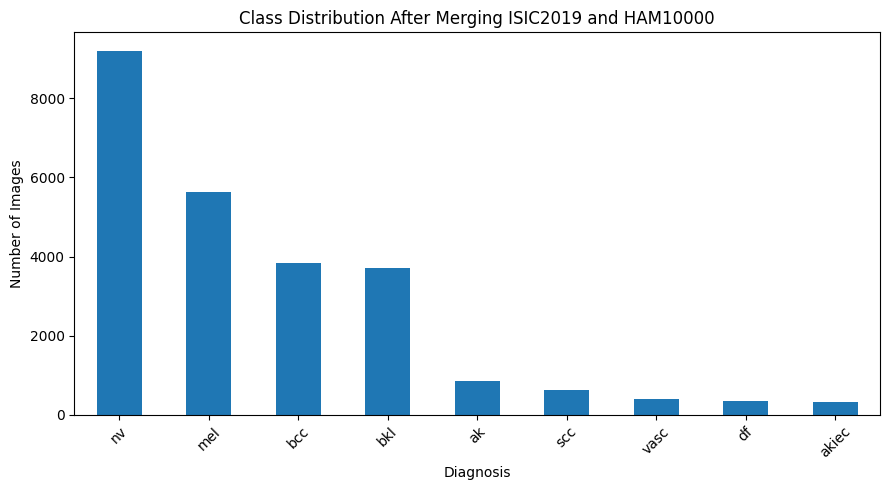

Largest-to-smallest class ratio: 28.14


In [48]:
import pandas as pd
import matplotlib.pyplot as plt

class_counts = combined_df["diagnosis"].value_counts()

class_percentages = (
    class_counts / class_counts.sum() * 100
)

imbalance_table = pd.DataFrame({
    "image_count": class_counts,
    "percentage": class_percentages.round(2)
})

display(imbalance_table)

plt.figure(figsize=(9, 5))

class_counts.plot(kind="bar")

plt.title("Class Distribution After Merging ISIC2019 and HAM10000")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Calculate imbalance ratio
if len(class_counts) > 0 and class_counts.min() > 0:
    print(
        "Largest-to-smallest class ratio:",
        round(class_counts.max() / class_counts.min(), 2)
    )

##**PREPROCESSING**

# split data using lesion id
ISIC columns:
['image_name', 'patient_id', 'sex', 'age_approx', 'anatom_site_general_challenge', 'diagnosis', 'benign_malignant', 'target', 'tfrecord', 'width', 'height', 'matched_filename', 'source', 'sha256', 'diagnosis_norm', 'image_path']

HAM columns:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'image_path', 'sha256', 'dx_norm']

In [49]:

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

IMAGE_COL = "image_path"
LABEL_COL = "diagnosis"
GROUP_COL = "group_id"
SITE_COL = "anatom_site_general_challenge"
AGE_COL = "age"
SEX_COL = "sex"

SEED = 42


def fill_within_lesion(df, cols, group_col):
    df = df.copy()

   #fill missing values
    for col in cols:
        df[col] = df[col].fillna(
            df.groupby(group_col, dropna=True)[col].transform("first")
        )

    return df


def make_split(df, label_col, seed=SEED,
               n_splits=20, n_test=3, n_val=3):

    if n_test + n_val >= n_splits:
        raise ValueError("n_test + n_val لازم يكون أقل من n_splits")

    sgkf = StratifiedGroupKFold(
        n_splits=n_splits,
        shuffle=True,
        random_state=seed
    )

    split = np.array(["train"] * len(df), dtype=object)

    for fold, (_, idx) in enumerate(
        sgkf.split(df, df[label_col], df["_group"])
    ):
        if fold < n_test:
            split[idx] = "test"
        elif fold < n_test + n_val:
            split[idx] = "val"

    return split


def prepare_metadata(df):
    df = df.copy().reset_index(drop=True)

    # التأكد من وجود الأعمدة المطلوبة
    required_cols = [
        IMAGE_COL, LABEL_COL, GROUP_COL,
        SITE_COL, AGE_COL, SEX_COL
    ]

    missing_cols = [c for c in required_cols if c not in df.columns]

    if missing_cols:
        raise ValueError(f"أعمدة غير موجودة: {missing_cols}")

    # استبعاد الصفوف التي لا تحتوي على label أو image path
    df = df.dropna(subset=[IMAGE_COL, LABEL_COL]).reset_index(drop=True)

    # تحويل السن لأرقام، والقيم غير الصالحة تصبح NaN
    df[AGE_COL] = pd.to_numeric(df[AGE_COL], errors="coerce")

    cols = [SITE_COL, AGE_COL, SEX_COL]

    print("=== Missing قبل المعالجة ===")
    print(df[cols].isna().sum().to_string())

    # 1. ملء البيانات الناقصة من صور الآفة نفسها
    df = fill_within_lesion(df, cols, GROUP_COL)

    print("\n=== Missing بعد الملء داخل الآفة ===")
    print(df[cols].isna().sum().to_string())

    # 2. كل مجموعة تظل في split واحد
    # لو group_id ناقص، نستخدم image_path كمجموعة مستقلة
    df["_group"] = (
        df[GROUP_COL]
        .astype("object")
        .where(df[GROUP_COL].notna(), df[IMAGE_COL].astype(str))
    )

    # نتأكد إن كل فئة لها عدد كافٍ من المجموعات
    groups_per_class = df.groupby(LABEL_COL)["_group"].nunique()

    if groups_per_class.min() < 20:
        raise ValueError(
            "بعض الفئات فيها أقل من 20 مجموعة مستقلة. "
            "قللي n_splits بعد مراجعة groups_per_class."
        )

    df["split"] = make_split(df, LABEL_COL)

    # 3. معالجة القيم المتبقية باستخدام بيانات train فقط
    train = df[df["split"] == "train"]

    # مؤشرات توضح إن القيمة كانت ناقصة
    df["age_missing"] = df[AGE_COL].isna().astype(int)
    df["site_missing"] = df[SITE_COL].isna().astype(int)
    df["sex_missing"] = df[SEX_COL].isna().astype(int)

    # الوسيط محسوب من train فقط
    age_median = train[AGE_COL].median()

    if pd.isna(age_median):
        age_median = 0

    df[AGE_COL] = df[AGE_COL].fillna(age_median)
    df[SITE_COL] = df[SITE_COL].fillna("unknown")
    df[SEX_COL] = df[SEX_COL].fillna("unknown")

    # 4. التحقق من النتيجة
    print("\n=== Missing في النهاية ===")
    print(df[cols].isna().sum().to_string())

    leakage = (
        df.groupby("_group")["split"].nunique() > 1
    ).sum()

    print(f"\nGroups موجودة في أكثر من split: {leakage}")

    print("\nعدد الصور في كل split:")
    print(df["split"].value_counts().to_string())

    print("\nنسبة كل فئة داخل كل split (%):")
    print(
        (
            pd.crosstab(
                df[LABEL_COL],
                df["split"],
                normalize="columns"
            ) * 100
        ).round(2).to_string()
    )

    print("\nنسبة كل split من إجمالي الصور (%):")
    print(
        (df["split"].value_counts(normalize=True) * 100)
        .round(2).to_string()
    )

    return df.drop(columns=["_group"])


# تشغيل الكود على الـ DataFrame الموجود بالفعل
clean_df = prepare_metadata(combined_df)

# حفظ ملف البيانات بعد المعالجة
from pathlib import Path

METADATA_CLEAN_PATH = Path.cwd() / "metadata_clean.csv"
clean_df.to_csv(METADATA_CLEAN_PATH, index=False)

# Conservation and split-integrity checks
assert len(clean_df) == len(combined_df), (
    "Some rows disappeared between combined_df and clean_df."
)
assert clean_df["split"].notna().all(), "Some rows have no split assignment."
assert set(clean_df["split"].unique()) == {"train", "val", "test"}
assert clean_df["image_path"].isna().sum() == 0
assert clean_df["diagnosis"].isna().sum() == 0

group_split_counts = clean_df.groupby("group_id")["split"].nunique()
assert (group_split_counts <= 1).all(), "A group appears in multiple splits."

hash_rows = clean_df.dropna(subset=["sha256"])
hash_split_counts = hash_rows.groupby("sha256")["split"].nunique()
assert not (hash_split_counts > 1).any(), "An identical image hash crosses splits."

print("Metadata saved:", METADATA_CLEAN_PATH)
print("Rows in combined_df:", len(combined_df))
print("Rows in clean_df:", len(clean_df))
print("Rows in train/val/test:", clean_df["split"].value_counts().to_dict())
print("All rows assigned exactly one split; group/hash leakage checks passed.")

=== Missing قبل المعالجة ===
anatom_site_general_challenge    957
age                              245
sex                                0

=== Missing بعد الملء داخل الآفة ===
anatom_site_general_challenge    957
age                              245
sex                                0

=== Missing في النهاية ===
anatom_site_general_challenge    0
age                              0
sex                              0

Groups موجودة في أكثر من split: 0

عدد الصور في كل split:
split
train    17464
test      3753
val       3713

نسبة كل فئة داخل كل split (%):
split       test  train    val
diagnosis                     
ak          3.28   3.44   3.66
akiec       1.57   1.32   1.02
bcc        16.09  14.96  16.54
bkl        14.73  14.93  14.79
df          1.31   1.36   1.80
mel        21.88  22.93  21.55
nv         36.88  36.90  37.03
scc         2.53   2.57   2.29
vasc        1.73   1.61   1.32

نسبة كل split من إجمالي الصور (%):
split
train    70.05
test     15.05
val      14.89
Metadata

In [50]:
#check every class in 3 splits
class_split_counts = pd.crosstab(
    clean_df["diagnosis"],
    clean_df["split"]
)

print(class_split_counts)

# الفئات غير الموجودة في أي split
for split_name in ["train", "val", "test"]:
    if split_name not in class_split_counts.columns:
        class_split_counts[split_name] = 0

missing_classes = class_split_counts[
    (class_split_counts["train"] == 0) |
    (class_split_counts["val"] == 0) |
    (class_split_counts["test"] == 0)
]

print("\nClasses missing from at least one split:")
print(missing_classes)


split      test  train   val
diagnosis                   
ak          123    600   136
akiec        59    230    38
bcc         604   2612   614
bkl         553   2607   549
df           49    238    67
mel         821   4004   800
nv         1384   6444  1375
scc          95    448    85
vasc         65    281    49

Classes missing from at least one split:
Empty DataFrame
Columns: [test, train, val]
Index: []


In [51]:
#نفس محتوى الصوره مش موجود فى اكتر من split
# تجاهل الصفوف التي ليس لها hash
hash_df = clean_df.dropna(subset=["sha256"])

# عدد الـ splits المختلفة لكل hash
hash_splits = hash_df.groupby("sha256")["split"].nunique()

leaked_hashes = hash_splits[hash_splits > 1]

print("Duplicate image hashes across splits:", len(leaked_hashes))

if len(leaked_hashes) == 0:
    print("PASS: No identical images across train/val/test.")
else:
    print("WARNING: Identical images exist across different splits.")

    print(
        hash_df[hash_df["sha256"].isin(leaked_hashes.index)]
        [["image_path", "source", "sha256", "split"]]
        .sort_values("sha256")
        .head(20)
        .to_string(index=False)
    )

Duplicate image hashes across splits: 0
PASS: No identical images across train/val/test.


#image preprocess

In [52]:
from pathlib import Path

for base in [Path("/kaggle/working"), Path("/content")]:
    if base.exists():
        print(f"\nFiles in {base}:")
        for p in base.rglob("Skin_Dataset.zip"):
            print(p)


Files in /kaggle/working:
/kaggle/working/Skin_Dataset.zip

Files in /content:


In [53]:
from pathlib import Path
import zipfile
import pandas as pd

ZIP_PATH = Path('/content/Skin_Dataset.zip')#"/kaggle/working/Skin_Dataset.zip"
EXTRACT_DIR = Path("/kaggle/working/Skin_Dataset")#"/kaggle/working/Skin_Dataset"

# فك الضغط لو المجلد مش موجود أو فاضي
if not EXTRACT_DIR.exists() or not any(EXTRACT_DIR.iterdir()):
    with zipfile.ZipFile(ZIP_PATH, "r") as z:
        z.extractall("/kaggle/working")

print("Dataset folder exists:", EXTRACT_DIR.exists())

# عرض بعض الملفات الموجودة
files = list(EXTRACT_DIR.rglob("*"))
image_files = [
    p for p in files
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
]

print("Number of images found:", len(image_files))
print("Sample image paths:")
for p in image_files[:5]:
    print(p)


Dataset folder exists: True
Number of images found: 24930
Sample image paths:
/kaggle/working/Skin_Dataset/images/010752_ISIC_0069255.jpg
/kaggle/working/Skin_Dataset/images/009653_ISIC_0066547.jpg
/kaggle/working/Skin_Dataset/images/009273_ISIC_0065657.jpg
/kaggle/working/Skin_Dataset/images/008313_ISIC_0063261.jpg
/kaggle/working/Skin_Dataset/images/015493_ISIC_0024882.jpg


In [54]:
#check pathes
CSV_PATH = Path.cwd() / "metadata_clean.csv"

clean_df = pd.read_csv(CSV_PATH)

print(clean_df.columns.tolist())
print(clean_df[["image_path", "diagnosis", "split"]].head())


['image_path', 'diagnosis', 'source', 'sha256', 'lesion_id', 'group_id', 'age', 'sex', 'anatom_site_general_challenge', 'split', 'age_missing', 'site_missing', 'sex_missing']
                                         image_path diagnosis  split
0              /content/isic/train/ISIC_0000002.jpg       mel  train
1              /content/isic/train/ISIC_0000004.jpg       mel    val
2              /content/isic/train/ISIC_0000013.jpg       mel  train
3  /content/isic/train/ISIC_0000022_downsampled.jpg       mel   test
4  /content/isic/train/ISIC_0000026_downsampled.jpg       mel  train


In [55]:
from pathlib import Path

# افحصي أول 10 مسارات كما هي مسجلة في CSV
for p in clean_df["image_path"].dropna().head(10):
    print(Path(p).exists(), p)


True /content/isic/train/ISIC_0000002.jpg
True /content/isic/train/ISIC_0000004.jpg
True /content/isic/train/ISIC_0000013.jpg
True /content/isic/train/ISIC_0000022_downsampled.jpg
True /content/isic/train/ISIC_0000026_downsampled.jpg
True /content/isic/train/ISIC_0000029_downsampled.jpg
True /content/isic/train/ISIC_0000030_downsampled.jpg
True /content/isic/train/ISIC_0000031_downsampled.jpg
True /content/isic/train/ISIC_0000035_downsampled.jpg
True /content/isic/train/ISIC_0000036_downsampled.jpg


In [56]:

import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

tf.keras.utils.set_random_seed(SEED)

# استخدام الـ metadata التي جهزناها بالفعل
df = clean_df.copy().reset_index(drop=True)

# التأكد من البيانات الأساسية
df = df.dropna(subset=["image_path", "diagnosis", "split"]).copy()

df["image_path"] = df["image_path"].astype(str)
df["diagnosis"] = df["diagnosis"].astype(str).str.strip()
df["split"] = df["split"].astype(str).str.lower().str.strip()

print("Images:", len(df))
print("\nSplit counts:")
print(df["split"].value_counts())

print("\nClass counts:")
print(df["diagnosis"].value_counts())

# التأكد من صحة المسارات
assert df["image_path"].map(lambda p: Path(p).is_file()).all(), \
    "Some image paths are invalid!"

assert set(df["split"].unique()) == {"train", "val", "test"}, \
    "Expected split values: train, val, test"

# ترتيب ثابت للفئات وترميزها إلى أرقام
class_names = sorted(df["diagnosis"].unique())
class_to_idx = {name: idx for idx, name in enumerate(class_names)}
idx_to_class = {idx: name for name, idx in class_to_idx.items()}

df["label"] = df["diagnosis"].map(class_to_idx).astype("int32")

NUM_CLASSES = len(class_names)

print("\nClasses:", class_names)
print("Number of classes:", NUM_CLASSES)


Images: 24930

Split counts:
split
train    17464
test      3753
val       3713
Name: count, dtype: int64

Class counts:
diagnosis
nv       9203
mel      5625
bcc      3830
bkl      3709
ak        859
scc       628
vasc      395
df        354
akiec     327
Name: count, dtype: int64

Classes: ['ak', 'akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'scc', 'vasc']
Number of classes: 9


In [57]:

def load_image(path, label):
    image_bytes = tf.io.read_file(path)

    # يدعم JPEG وPNG
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    # تغيير الحجم مع الحفاظ على نسبة الأبعاد
    image = tf.image.resize_with_pad(
        image,
        IMG_SIZE,
        IMG_SIZE,
        method="bilinear"
    )

    # EfficientNet في Keras يتضمن preprocessing داخليًا.
    # لذلك لا نقسم الصورة على 255 هنا.
    image = tf.cast(image, tf.float32)

    return image, label


def make_dataset(dataframe, training=False):
    paths = dataframe["image_path"].to_numpy()
    labels = dataframe["label"].to_numpy(dtype=np.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=min(len(dataframe), 3000),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds


train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

print("Train images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))


I0000 00:00:1792938669.775882      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792938669.781015      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Train images: 17464
Validation images: 3713
Test images: 3753


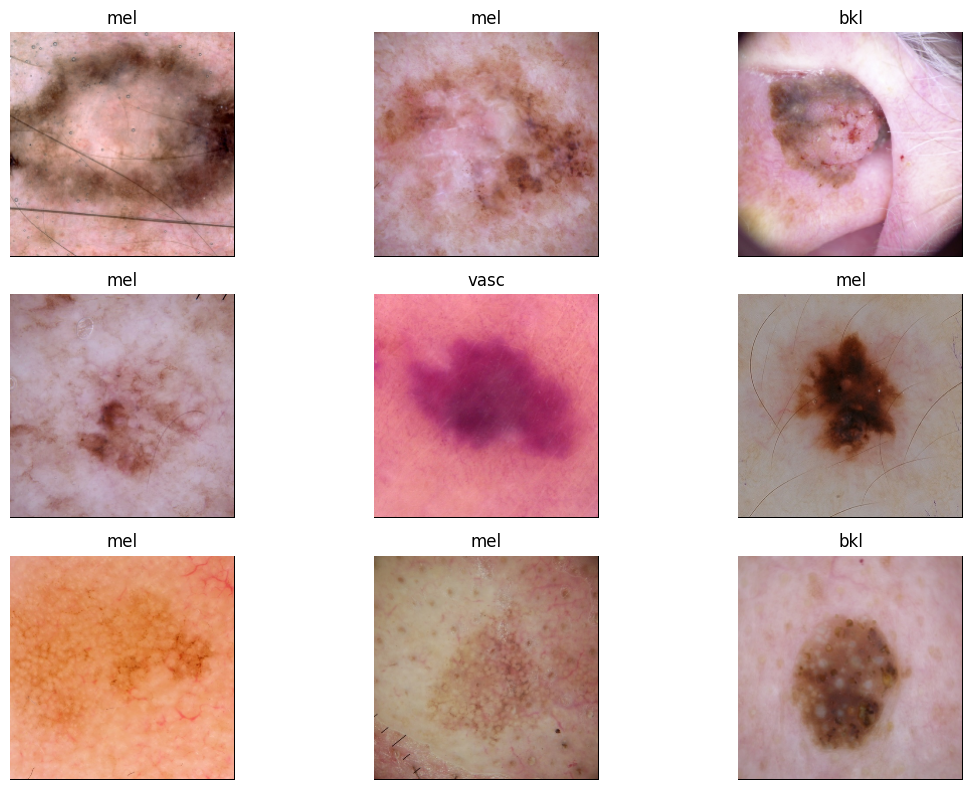

In [58]:
#check image and label
plt.figure(figsize=(12, 8))

for images, labels in train_ds.take(1):
    n = min(9, len(images))

    for i in range(n):
        plt.subplot(3, 3, i + 1)
        plt.imshow(tf.cast(images[i], tf.uint8).numpy())
        plt.title(idx_to_class[int(labels[i].numpy())])
        plt.axis("off")

plt.tight_layout()
plt.show()


# Version 1 — Original: train, val, test

In [59]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

SEED = 42
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

tf.keras.utils.set_random_seed(SEED)

# استخدام الداتا بعد الـ split الموجود بالفعل
df = clean_df.copy().reset_index(drop=True)

# نفس الكلاسات في كل النسخ
class_names = sorted(df["diagnosis"].dropna().unique())
class_to_idx = {name: i for i, name in enumerate(class_names)}
idx_to_class = {i: name for name, i in class_to_idx.items()}

df["label"] = df["diagnosis"].map(class_to_idx).astype("int32")

# Version 1: Original dataframes
train_original = df[df["split"] == "train"].copy().reset_index(drop=True)
val_original = df[df["split"] == "val"].copy().reset_index(drop=True)
test_original = df[df["split"] == "test"].copy().reset_index(drop=True)

# طباعة كل متغير لوحده
print("===== TRAIN ORIGINAL =====")
print(train_original.head())
print("Shape:", train_original.shape)

print("\n===== VALIDATION ORIGINAL =====")
print(val_original.head())
print("Shape:", val_original.shape)

print("\n===== TEST ORIGINAL =====")
print(test_original.head())
print("Shape:", test_original.shape)

print("\nClasses:", class_names)


===== TRAIN ORIGINAL =====
                                         image_path diagnosis    source  \
0              /content/isic/train/ISIC_0000002.jpg       mel  ISIC2019   
1              /content/isic/train/ISIC_0000013.jpg       mel  ISIC2019   
2  /content/isic/train/ISIC_0000026_downsampled.jpg       mel  ISIC2019   
3  /content/isic/train/ISIC_0000029_downsampled.jpg       mel  ISIC2019   
4  /content/isic/train/ISIC_0000030_downsampled.jpg       mel  ISIC2019   

                                              sha256 lesion_id  \
0  fc30b8a43cc0ae238fcaba71155d831dfb86e9eb2ccc57...       NaN   
1  b6a83b742377478ca79a2bb4923114ae78352fbb38b61c...       NaN   
2  05806758b5db7bc44cba270d868c55dc2957581f5a2f0c...       NaN   
3  c3217f21981a20395f2a58ad2a531796ba3404af925d58...       NaN   
4  2ce4dd519c00f1269145a6b938c196a09fc2b0e14acd7e...       NaN   

                                  group_id   age     sex  \
0              ISIC_IMAGE_ISIC_0000002.jpg  60.0  female   
1    

In [60]:
#this for 3versions
def load_original_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize_with_pad(
        image, IMG_SIZE, IMG_SIZE,
        method="bilinear"
    )

    image = tf.cast(image, tf.float32)

    return image, label


def make_tf_dataset(dataframe, loader, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        dataframe["image_path"].to_numpy(),
        dataframe["label"].to_numpy(dtype=np.int32)
    ))

    if training:
        ds = ds.shuffle(
            min(len(dataframe), 3000),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(loader, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)

    return ds


train_original_ds = make_tf_dataset(
    train_original, load_original_image, training=True
)
val_original_ds = make_tf_dataset(
    val_original, load_original_image
)
test_original_ds = make_tf_dataset(
    test_original, load_original_image
)

# عرض أول batch من كل متغير
for name, dataset in [
    ("Train Original", train_original_ds),
    ("Validation Original", val_original_ds),
    ("Test Original", test_original_ds)
]:
    images, labels = next(iter(dataset))
    print(name, images.shape, labels.shape)


Train Original (32, 224, 224, 3) (32,)
Validation Original (32, 224, 224, 3) (32,)
Test Original (32, 224, 224, 3) (32,)


In [61]:
from google.colab import drive
drive.flush_and_unmount()

Drive not mounted, so nothing to flush and unmount.


In [62]:
from google.colab import drive
drive.mount('/content/drive')
fdf

NotImplementedError: Mounting drive is unsupported in this environment. Use PyDrive2 instead. See examples at https://colab.research.google.com/notebooks/io.ipynb#scrollTo=7taylj9wpsA2.

In [63]:
import shutil
from pathlib import Path
from tqdm.auto import tqdm

# مكان حفظ الداتا الأصلية
# Use Google Drive when mounted in Colab; otherwise save in the current workspace.
DRIVE_DIR = Path("/kaggle/input/datasets/beshoyshohdy/skin-data")
if DRIVE_DIR.exists():
    SAVE_DIR = DRIVE_DIR / "tensorflow_original"
else:
    SAVE_DIR = Path.cwd() / "tensorflow_original"

SAVE_DIR.mkdir(parents=True, exist_ok=True)

# استخدام الـ DataFrames الموجودة بالفعل
original_splits = {
    "train": train_original,
    "val": val_original,
    "test": test_original
}

for split, split_df in original_splits.items():

    output_dir = SAVE_DIR / split
    output_dir.mkdir(parents=True, exist_ok=True)

    saved_count = 0
    missing_count = 0

    for _, row in tqdm(
        split_df.iterrows(),
        total=len(split_df),
        desc=f"Saving {split}"
    ):
        src = Path(row["image_path"])

        # اسم الصورة مع اسم الكلاس
        dst = output_dir / f"{row['diagnosis']}_{src.name}"

        if not src.exists():
            missing_count += 1
            continue

        # تجنب نسخ الصورة مرة أخرى إذا كانت موجودة
        if not dst.exists():
            shutil.copy2(src, dst)

        saved_count += 1

    print(f"\n{split.upper()}")
    print(f"Images saved: {saved_count}")
    print(f"Missing images: {missing_count}")

# حفظ بيانات كل الصور والـ labels والـ split
metadata_path = SAVE_DIR / "metadata.csv"
df.to_csv(metadata_path, index=False)

print("\nOriginal TensorFlow dataset saved successfully!")
print("Dataset location:", SAVE_DIR)
print("Metadata location:", metadata_path)

Saving train:   0%|          | 0/17464 [00:00<?, ?it/s]


TRAIN
Images saved: 17464
Missing images: 0


Saving val:   0%|          | 0/3713 [00:00<?, ?it/s]


VAL
Images saved: 3713
Missing images: 0


Saving test:   0%|          | 0/3753 [00:00<?, ?it/s]


TEST
Images saved: 3753
Missing images: 0

Original TensorFlow dataset saved successfully!
Dataset location: /kaggle/working/tensorflow_original
Metadata location: /kaggle/working/tensorflow_original/metadata.csv


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/tensorflow_original")

for p in ROOT.iterdir():
    if p.is_dir():
        print(p.name, ":", sum(1 for f in p.rglob("*") if f.is_file()))
    else:
        print("File:", p.name)

In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/tensorflow_original")

for p in ROOT.iterdir():
    if p.is_dir():
        print(p.name, "->", sum(1 for f in p.iterdir() if f.is_file()), "files")
    else:
        print(p.name)

In [ ]:
import shutil
from google.colab import files

# مسار الفولدر الأصلي
folder_path = "/content/drive/MyDrive/tensorflow_original"

# مكان واسم ملف ZIP
zip_path = "/content/tensorflow_original"

# ضغط الفولدر
shutil.make_archive(zip_path, "zip", folder_path)

print("ZIP file created successfully!")

# تنزيل الملف على جهازك
files.download(zip_path + ".zip")

# version 2: tensorflow with augmented

In [ ]:
augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip(
        "horizontal_and_vertical",
        seed=SEED
    ),
    tf.keras.layers.RandomRotation(
        factor=15 / 360,
        fill_mode="reflect",
        seed=SEED
    ),
    tf.keras.layers.RandomZoom(
        height_factor=(-0.10, 0.10),
        width_factor=(-0.10, 0.10),
        fill_mode="reflect",
        seed=SEED
    ),
    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05,
        fill_mode="reflect",
        seed=SEED
    ),
    tf.keras.layers.RandomContrast(
        0.10,
        seed=SEED
    )
], name="data_augmentation")


In [ ]:
train_augmented = train_original.copy()
val_augmented = val_original.copy()
test_augmented = test_original.copy()

# الـ DataLoaders نفسها تقرأ الصور الأصلية.
# الـ augmentation سيُطبق داخل الموديل أثناء التدريب.
train_augmented_ds = make_tf_dataset(
    train_augmented, load_original_image, training=True
)
val_augmented_ds = make_tf_dataset(
    val_augmented, load_original_image
)
test_augmented_ds = make_tf_dataset(
    test_augmented, load_original_image
)

print("Train augmented version:", len(train_augmented))
print("Validation:", len(val_augmented))
print("Test:", len(test_augmented))


In [ ]:
#when build model with augmented use this
#inputs = tf.keras.Input(shape=(224, 224, 3))

#x = augmentation(inputs)
#x = base_model(x, training=False)

#version 3:transformer

In [ ]:

# Version 3: Transformer dataframes based on model
train_transformer = train_original.copy()
val_transformer = val_original.copy()
test_transformer = test_original.copy()


def load_transformer_image(path, label):
    image = tf.io.read_file(path)
    image = tf.io.decode_image(
        image, channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize_with_pad(
        image, IMG_SIZE, IMG_SIZE,
        method="bilinear"
    )

    # نطاق 0 إلى 1
    image = tf.cast(image, tf.float32) / 255.0

    return image, label


train_transformer_ds = make_tf_dataset(
    train_transformer,
    load_transformer_image,
    training=True
)

val_transformer_ds = make_tf_dataset(
    val_transformer,
    load_transformer_image
)

test_transformer_ds = make_tf_dataset(
    test_transformer,
    load_transformer_image
)

for name, dataset in [
    ("Train Transformer", train_transformer_ds),
    ("Validation Transformer", val_transformer_ds),
    ("Test Transformer", test_transformer_ds)
]:
    images, labels = next(iter(dataset))
    print(
        name,
        "Images:", images.shape,
        "Labels:", labels.shape,
        "Min:", float(tf.reduce_min(images)),
        "Max:", float(tf.reduce_max(images))
    )


# class waight (trying just you can change it for model or keep it)

In [ ]:
classes_in_train = np.sort(train_df["label"].unique())

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes_in_train,
    y=train_df["label"].to_numpy()
)

class_weights = {
    int(class_id): float(weight)
    for class_id, weight in zip(classes_in_train, weights)
}

print("Class weights:")
for class_id, weight in class_weights.items():
    print(f"{idx_to_class[class_id]}: {weight:.3f}")


In [67]:
import shutil

shutil.make_archive(
    "/kaggle/working/tensorflow_original",
    "zip",
    root_dir="/kaggle/working",
    base_dir="tensorflow_original"
)

'/kaggle/working/tensorflow_original.zip'

In [68]:
import shutil

shutil.rmtree("/kaggle/working/tensorflow_original")

In [69]:
from IPython.display import FileLink, display

display(FileLink("/kaggle/working/tensorflow_original.zip"))

/kaggle/working/tensorflow_original.zip